# **Dataset Description**

# **Loading the data**

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("denishazamuke/synthetic-mobile-money-transaction-dataset")

print("Path to dataset files:", path)

100%|██████████| 131M/131M [00:01<00:00, 70.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/denishazamuke/synthetic-mobile-money-transaction-dataset/versions/1


In [ ]:
import pandas as pd
import os

# Path to the dataset directory
dataset_path = "/root/.cache/kagglehub/datasets/denishazamuke/synthetic-mobile-money-transaction-dataset/versions/1"

# List all files in the dataset directory
files = os.listdir(dataset_path)
print("Available files:", files)

# Load one or more CSV files
data = pd.read_csv(os.path.join(dataset_path, files[0]))  # Replace files[0] with the desired file
print(data.head())


Available files: ['MoMTSim_20240722202413_1000_dataset.csv']
   step transactionType  amount         initiator  oldBalInitiator  \
0     0         PAYMENT  579.16  4018807983755588            29.32   
1     0        TRANSFER   39.03  4610593854752035            39.03   
2     0        TRANSFER   21.78  4840578447365454            21.78   
3     0         PAYMENT  570.22  4958066799829630             5.29   
4     0         PAYMENT  574.80  4149196095918843            82.63   

   newBalInitiator         recipient  oldBalRecipient  newBalRecipient  \
0            29.32        30-0000345             0.00             0.00   
1             0.00  4944921135715488            55.94            94.98   
2             0.00  4305579785620656            58.09            79.88   
3             5.29        00-0000388             0.00             0.00   
4            82.63        80-0005320             0.00             0.00   

   isFraud  
0        0  
1        1  
2        1  
3        0  
4       

In [ ]:
data.tail(5)
#columns ---> features

,step,transactionType,amount,initiator,oldBalInitiator,newBalInitiator,recipient,oldBalRecipient,newBalRecipient,isFraud
4225953,192,TRANSFER,30.21,4553340044344003,30.21,0.00,4857848274256757,6724271.67,6724301.88,1
4225954,192,PAYMENT,564.88,4661148030050354,0.00,0.00,99-0001567,518107.98,518107.98,0
4225955,192,PAYMENT,697.48,4324436406765252,19012756.07,19012058.59,76-0004439,315608.97,316306.44,0
4225956,192,TRANSFER,19611.79,4324436406765252,19012058.59,18992446.80,4195960558852622,16896.95,36508.74,1
4225957,192,PAYMENT,597.90,4981498694591828,561.09,561.09,61-0004985,422939.22,422939.22,0


# **Data Pre-Processing**

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4225958 entries, 0 to 4225957
Data columns (total 10 columns):
 #   Column           Dtype  
---  ------           -----  
 0   step             int64  
 1   transactionType  object 
 2   amount           float64
 3   initiator        int64  
 4   oldBalInitiator  float64
 5   newBalInitiator  float64
 6   recipient        object 
 7   oldBalRecipient  float64
 8   newBalRecipient  float64
 9   isFraud          int64  
dtypes: float64(5), int64(3), object(2)
memory usage: 322.4+ MB


In [ ]:
print(data.describe())
print(data['transactionType'].value_counts())
print(data['isFraud'].value_counts())


               step        amount     initiator  oldBalInitiator  \
count  4.225958e+06  4.225958e+06  4.225958e+06     4.225958e+06   
mean   9.811771e+01  5.302139e+04  4.495008e+15     2.246055e+07   
std    5.573710e+01  2.708194e+06  2.912521e+14     6.418504e+07   
min    0.000000e+00  0.000000e+00  4.000000e+15    -1.999926e+05   
25%    5.000000e+01  9.444000e+01  4.237994e+15     4.681000e+01   
50%    9.900000e+01  5.966900e+02  4.491576e+15     3.655435e+03   
75%    1.470000e+02  1.708469e+04  4.747260e+15     2.344082e+05   
max    1.920000e+02  7.654805e+08  5.000000e+15     6.409231e+08   

       newBalInitiator  oldBalRecipient  newBalRecipient       isFraud  
count     4.225958e+06     4.225958e+06     4.225958e+06  4.225958e+06  
mean      2.246527e+07     1.685005e+06     1.703967e+06  5.284288e-01  
std       6.421561e+07     6.795783e+06     6.802160e+06  4.991912e-01  
min      -1.999926e+05    -7.477966e+04     0.000000e+00  0.000000e+00  
25%       0.000000e+00

## Checking null values in datasets

In [ ]:
data.isnull().sum()

,0
step,0
transactionType,0
amount,0
initiator,0
oldBalInitiator,0
newBalInitiator,0
recipient,0
oldBalRecipient,0
newBalRecipient,0
isFraud,0


## Checking duplicates in the datasets

In [ ]:
data.duplicated().sum()

0

## Remove duplicates in datasets

In [ ]:
data = data.drop_duplicates()

<ipython-input-14-50d4b23d6f77>:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='transactionType', order=data['transactionType'].value_counts().index, palette='viridis')


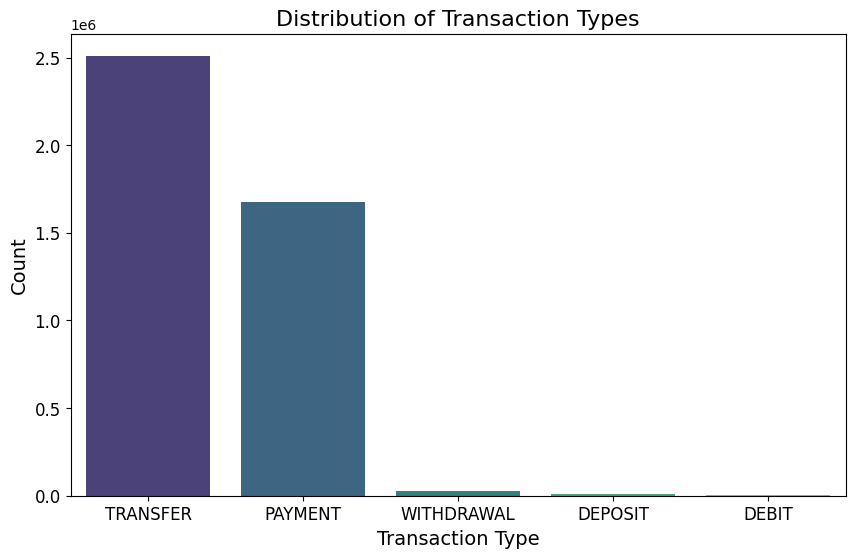

<ipython-input-14-50d4b23d6f77>:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='isFraud', palette='coolwarm')


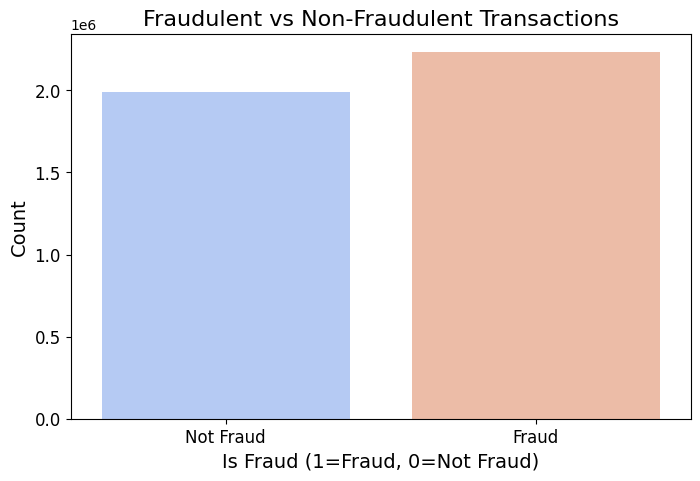

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot for transactionType
plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='transactionType', order=data['transactionType'].value_counts().index, palette='viridis')
plt.title('Distribution of Transaction Types', fontsize=16)
plt.xlabel('Transaction Type', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

# Plot for isFraud
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='isFraud', palette='coolwarm')
plt.title('Fraudulent vs Non-Fraudulent Transactions', fontsize=16)
plt.xlabel('Is Fraud (1=Fraud, 0=Not Fraud)', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks([0, 1], ['Not Fraud', 'Fraud'], fontsize=12)
plt.yticks(fontsize=12)
plt.show()


## Applying Label encoder to the TransactionType




In [ ]:
from sklearn.preprocessing import LabelEncoder

# Initialize the label encoder
label_encoder = LabelEncoder()

# Apply label encoding to the transactionType column
data['transactionType'] = label_encoder.fit_transform(data['transactionType'])

# Verify the conversion
print("Unique values after label encoding:", data['transactionType'].unique())
print("Mapping of categories to integers:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))


Unique values after label encoding: [2 3 1 4 0]
Mapping of categories to integers: {'DEBIT': 0, 'DEPOSIT': 1, 'PAYMENT': 2, 'TRANSFER': 3, 'WITHDRAWAL': 4}


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4225938 entries, 0 to 4225957
Data columns (total 10 columns):
 #   Column           Dtype  
---  ------           -----  
 0   step             int64  
 1   transactionType  int64  
 2   amount           float64
 3   initiator        int64  
 4   oldBalInitiator  float64
 5   newBalInitiator  float64
 6   recipient        object 
 7   oldBalRecipient  float64
 8   newBalRecipient  float64
 9   isFraud          int64  
dtypes: float64(5), int64(4), object(1)
memory usage: 354.7+ MB


In [ ]:
print("\nNumber of unique recipients:", data['recipient'].nunique())


Number of unique recipients: 22517


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data['recipient'] = le.fit_transform(data['recipient'])


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4225938 entries, 0 to 4225957
Data columns (total 10 columns):
 #   Column           Dtype  
---  ------           -----  
 0   step             int64  
 1   transactionType  int64  
 2   amount           float64
 3   initiator        int64  
 4   oldBalInitiator  float64
 5   newBalInitiator  float64
 6   recipient        int64  
 7   oldBalRecipient  float64
 8   newBalRecipient  float64
 9   isFraud          int64  
dtypes: float64(5), int64(5)
memory usage: 354.7 MB


## Correlation matrix

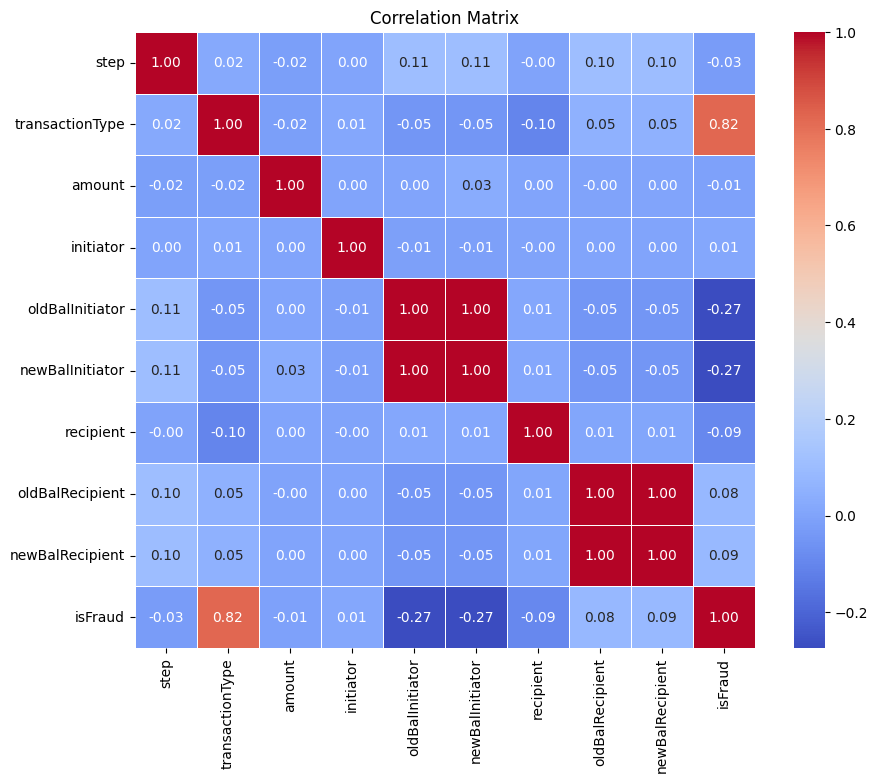

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualize the correlation matrix with a heatmap
plt.figure(figsize=(10, 8))
correlation_matrix = data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()


In [ ]:
print(correlation_matrix)

                     step  transactionType    amount  initiator  \
step             1.000000         0.023684 -0.017772   0.000787   
transactionType  0.023684         1.000000 -0.019752   0.013818   
amount          -0.017772        -0.019752  1.000000   0.000258   
initiator        0.000787         0.013818  0.000258   1.000000   
oldBalInitiator  0.108630        -0.045269  0.001075  -0.013033   
newBalInitiator  0.107995        -0.046779  0.033095  -0.013040   
recipient       -0.002857        -0.100415  0.001160  -0.001426   
oldBalRecipient  0.104396         0.050396 -0.001336   0.002484   
newBalRecipient  0.104243         0.052316  0.001777   0.002521   
isFraud         -0.028868         0.824741 -0.007688   0.011921   

                 oldBalInitiator  newBalInitiator  recipient  oldBalRecipient  \
step                    0.108630         0.107995  -0.002857         0.104396   
transactionType        -0.045269        -0.046779  -0.100415         0.050396   
amount             

Based on the correlation matrix we provided, here’s a detailed analysis of the relationships between the features in your dataset:

1. High Positive Correlations:
oldBalInitiator and newBalInitiator: Correlation of 0.999272. These two features are almost identical. This suggests that the old balance of the initiator is very strongly related to the new balance, meaning there is a minimal change in balance during transactions.

oldBalRecipient and newBalRecipient: Correlation of 0.999374. Similar to the initiator's balance, the recipient's old and new balances are also highly correlated.

newBalRecipient and newBalInitiator: Correlation of 0.104243 (though not very strong, it is still positive). There may be a slight relationship between the balances of initiator and recipient after the transaction.

2. Negative Correlations:
isFraud and oldBalInitiator / newBalInitiator: Both have a moderate negative correlation of around -0.273515 and -0.273952, suggesting that as the balance of the initiator increases, the likelihood of fraud decreases. This may indicate a lower fraud risk in higher-value transactions.

isFraud and recipient: Correlation of -0.092839 suggests a very weak negative correlation between fraud and the recipient.

isFraud and transactionType: High positive correlation of 0.824741. This indicates that certain transaction types are highly likely to be associated with fraudulent transactions. This feature seems to be a strong indicator of fraud in your dataset.

3. Low or Insignificant Correlations:
amount and other features: The correlation between amount and other features (like oldBalInitiator, newBalInitiator, etc.) is very weak, suggesting that the amount of the transaction doesn’t correlate strongly with other features like balances, recipients, or fraud occurrence.

recipient and most other features: The recipient feature has weak correlations with most other variables, indicating it might not be directly related to the transaction values or fraud risk.

4. Insights for Action:
transactionType and isFraud: This is the most informative relationship. Since transactionType strongly correlates with isFraud, this could be a key variable to monitor when building fraud detection models. You might consider encoding this feature and using it for model training.

Balance Features (oldBalInitiator, newBalInitiator, oldBalRecipient, newBalRecipient): Since these features are highly correlated with each other, they may introduce multicollinearity if included together in predictive models. It might be useful to keep just one (e.g., newBalInitiator or newBalRecipient) to avoid redundancy.

Fraud Detection: Features like transactionType, oldBalInitiator, and newBalInitiator have a significant relationship with isFraud. Consider using these features when developing models for fraud detection.

## Creating new features

In [ ]:
# Create new features from existing ones
data['balanceChangeInitiator'] = data['newBalInitiator'] - data['oldBalInitiator']
data['balanceChangeRecipient'] = data['newBalRecipient'] - data['oldBalRecipient']

# Amount to balance ratio (initiator)
data['amountToBalanceRatioInitiator'] = data['amount'] / (data['oldBalInitiator'] + 1e-6)  # Adding small value to avoid division by zero

# Transaction size relative to initiator's balance
data['transactionSizeRelativeToBalance'] = data['amount'] / (data['oldBalInitiator'] + 1e-6)

# Display the new features added
print("Feature Engineering - New Data:")
print(data[['balanceChangeInitiator', 'balanceChangeRecipient', 'amountToBalanceRatioInitiator', 'transactionSizeRelativeToBalance']].head())


Feature Engineering - New Data:
   balanceChangeInitiator  balanceChangeRecipient  \
0                    0.00                    0.00   
1                  -39.03                   39.04   
2                  -21.78                   21.79   
3                    0.00                    0.00   
4                    0.00                    0.00   

   amountToBalanceRatioInitiator  transactionSizeRelativeToBalance  
0                      19.753069                         19.753069  
1                       1.000000                          1.000000  
2                       1.000000                          1.000000  
3                     107.792040                        107.792040  
4                       6.956311                          6.956311  




1. balanceChangeInitiator:
Formula: data['balanceChangeInitiator'] = data['newBalInitiator'] - data['oldBalInitiator']
Purpose: This feature calculates how much the initiator's balance has changed due to the transaction. It’s important because large changes in the balance can indicate a significant transaction, which could be more likely to be fraudulent. By tracking balance changes, we get an idea of how the transaction affects the initiator's account.
2. balanceChangeRecipient:
Formula: data['balanceChangeRecipient'] = data['newBalRecipient'] - data['oldBalRecipient']
Purpose: Similar to the initiator, this feature tracks the change in the recipient's balance. It can be crucial for identifying patterns in the recipient’s account behavior and detecting fraudulent transfers that might involve rapid or unexplained changes.
3. amountToBalanceRatioInitiator:
Formula: data['amountToBalanceRatioInitiator'] = data['amount'] / (data['oldBalInitiator'] + 1e-6)
Purpose: This feature gives the ratio of the transaction amount to the initiator's current balance. If a user is making a transaction that represents a large portion of their balance, it might indicate suspicious behavior. The 1e-6 is added to avoid division by zero in case the balance is zero (though this is unlikely in a real-world scenario, it's a safeguard).
4. transactionSizeRelativeToBalance:
Formula: data['transactionSizeRelativeToBalance'] = data['amount'] / (data['oldBalInitiator'] + 1e-6)
Purpose: This feature compares the transaction size to the initiator’s balance, helping us understand how significant a given transaction is relative to their available balance. A large transaction relative to the balance could be an indicator of fraud or risky behavior.
Why These Features?
Transaction Behavior: Transactions that drastically change a user’s balance or are too large relative to the balance might be abnormal. By creating these new features, we can provide more context to the model about the size and impact of the transactions.
Fraud Detection: Many fraudulent transactions involve large, unexplained changes in balances, or they represent a significant percentage of the user’s balance. These features help the model understand the context better, enabling it to differentiate between legitimate and suspicious transactions.

# **Data Visualization**

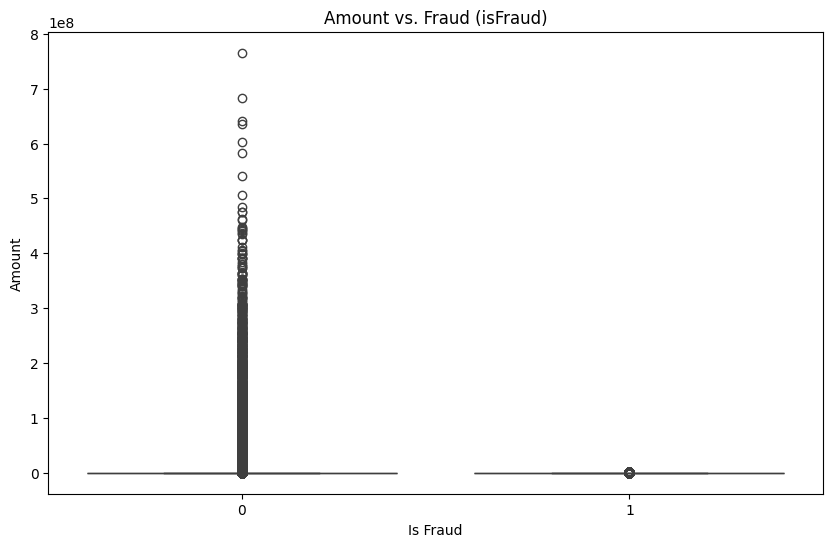

In [ ]:
# Amount vs Fraud (isFraud)
plt.figure(figsize=(10,6))
sns.boxplot(x='isFraud', y='amount', data=data)
plt.title('Amount vs. Fraud (isFraud)')
plt.xlabel('Is Fraud')
plt.ylabel('Amount')
plt.show()


## Distribution in Transaction type

<ipython-input-35-6eab0a3efe12>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='transactionType', data=data, palette='viridis')


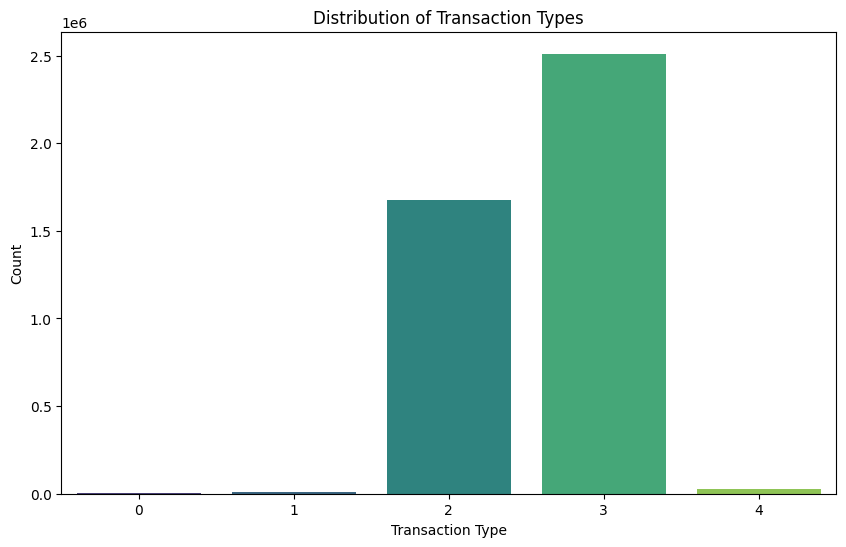

In [ ]:
# Distribution of Transaction Type
plt.figure(figsize=(10,6))
sns.countplot(x='transactionType', data=data, palette='viridis')
plt.title('Distribution of Transaction Types')
plt.xlabel('Transaction Type')
plt.ylabel('Count')
plt.show()


In [ ]:
# Split the dataset into features (X) and target (y)
X = data.drop(columns=['isFraud'])
y = data['isFraud']


## Splitting of Dataset into test and train sets(70%--->train and 30%--->test)

In [ ]:
from sklearn.model_selection import train_test_split

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


## Applying Standard scalar to the data

In [ ]:
from sklearn.preprocessing import StandardScaler

# Scale features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## Fitting data(Training data) to the model(LogisticRegression)

### **Scikit-Learn**
Randomforest classification
xgboost calssification
LightGbm Classification
adaboost Classification

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Initialize the Logistic Regression model
model = LogisticRegression(random_state=42)

# Train the model
model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

# Evaluate model
print("Accuracy Score: ", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy Score:  0.946938038243168

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.91      0.94    597576
           1       0.93      0.98      0.95    670206

    accuracy                           0.95   1267782
   macro avg       0.95      0.95      0.95   1267782
weighted avg       0.95      0.95      0.95   1267782


Confusion Matrix:
 [[545820  51756]
 [ 15515 654691]]


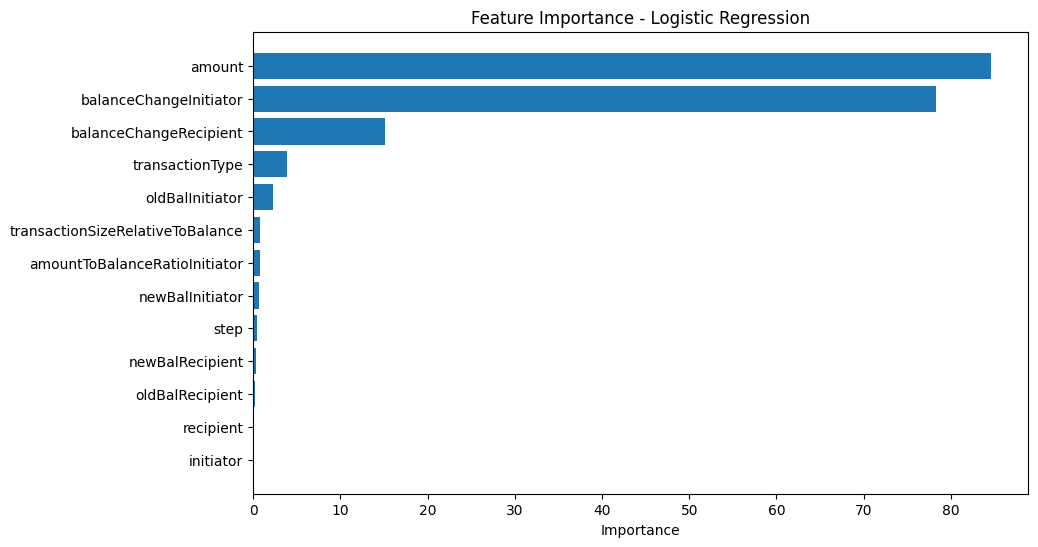

                             Feature  Importance
2                             amount   84.639911
9             balanceChangeInitiator   78.336017
10            balanceChangeRecipient   15.096504
1                    transactionType    3.819638
4                    oldBalInitiator    2.286910
12  transactionSizeRelativeToBalance    0.793245
11     amountToBalanceRatioInitiator    0.793245
5                    newBalInitiator    0.670746
0                               step    0.385945
8                    newBalRecipient    0.365799
7                    oldBalRecipient    0.159679
6                          recipient    0.059483
3                          initiator    0.047564


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression


log_reg = LogisticRegression(class_weight='balanced', random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Get the absolute value of the coefficients (feature importance)
importance = np.abs(log_reg.coef_[0])

# Create a DataFrame to display the feature importance
feature_importance_df = pd.DataFrame({
    'Feature': X_train.columns,  # Features from your dataset
    'Importance': importance
})

# Sort the features by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Plot the feature importance
plt.figure(figsize=(10, 6))
plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'])
plt.xlabel('Importance')
plt.title('Feature Importance - Logistic Regression')
plt.gca().invert_yaxis()  # To show the most important features at the top
plt.show()

# Display the sorted feature importance
print(feature_importance_df)
